# Example of the aitlas toolbox in the context of object detection in remote sensing images

## Import the required packages

In [ ]:
from aitlas.datasets import MASATIObjectDetectionDataset 
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN
import numpy as np

## Visualize images and objects witn bounding boxes

Total number of patches: 1896


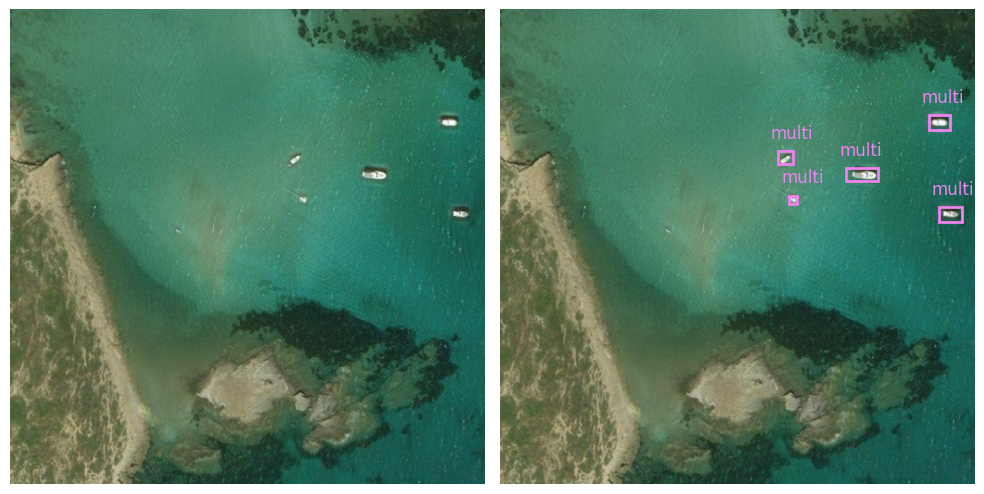

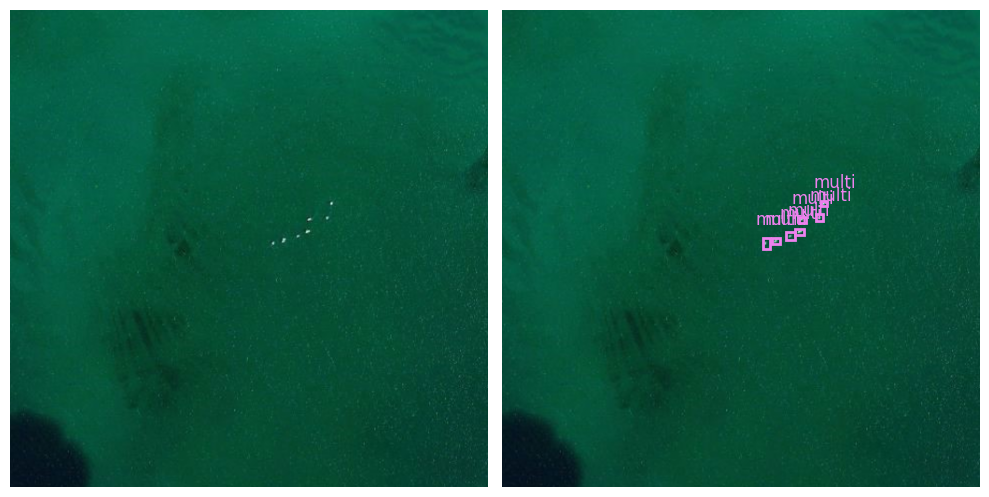

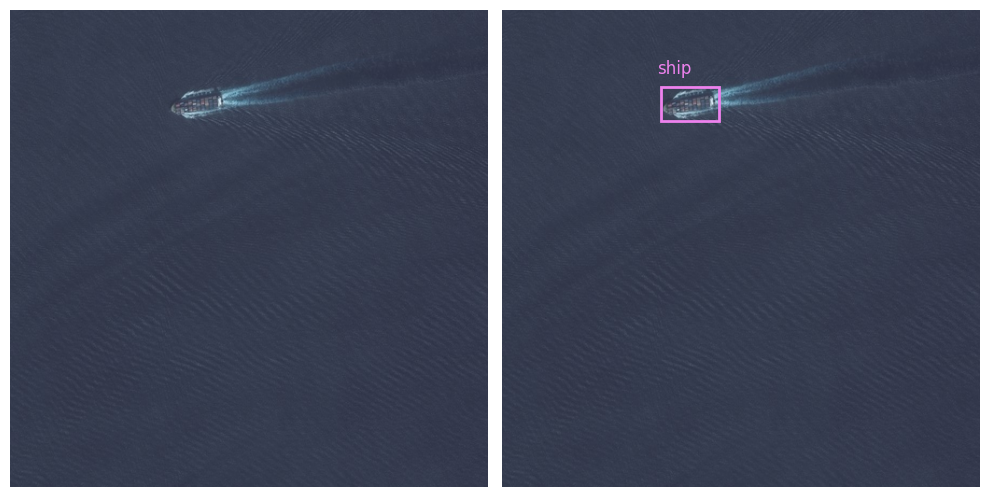

In [ ]:
dataset_config = {
    "image_dir": "./data/MASATI/object_detection/images/",
    "annotations_dir": "./data/MASATI/object_detection/labels/",
    "csv_file":"./data/MASATI/object_detection/train.csv",
}
dataset = MASATIObjectDetectionDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(10);
dataset.show_image(500);

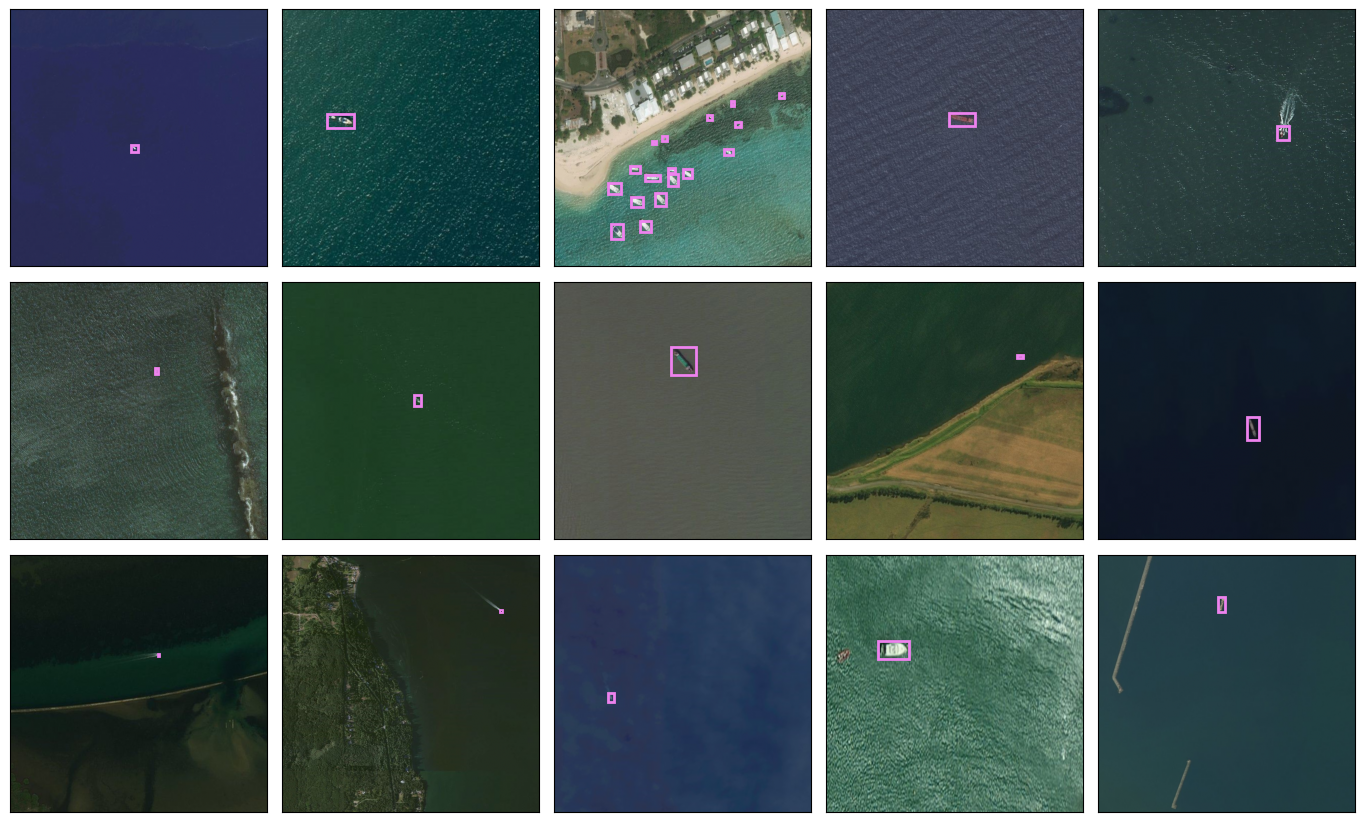

In [51]:
dataset.show_batch(15);

In [53]:
dataset.data_distribution_table()

,Label,Count
0,ship,816
1,multi,1581
2,coast_ship,854


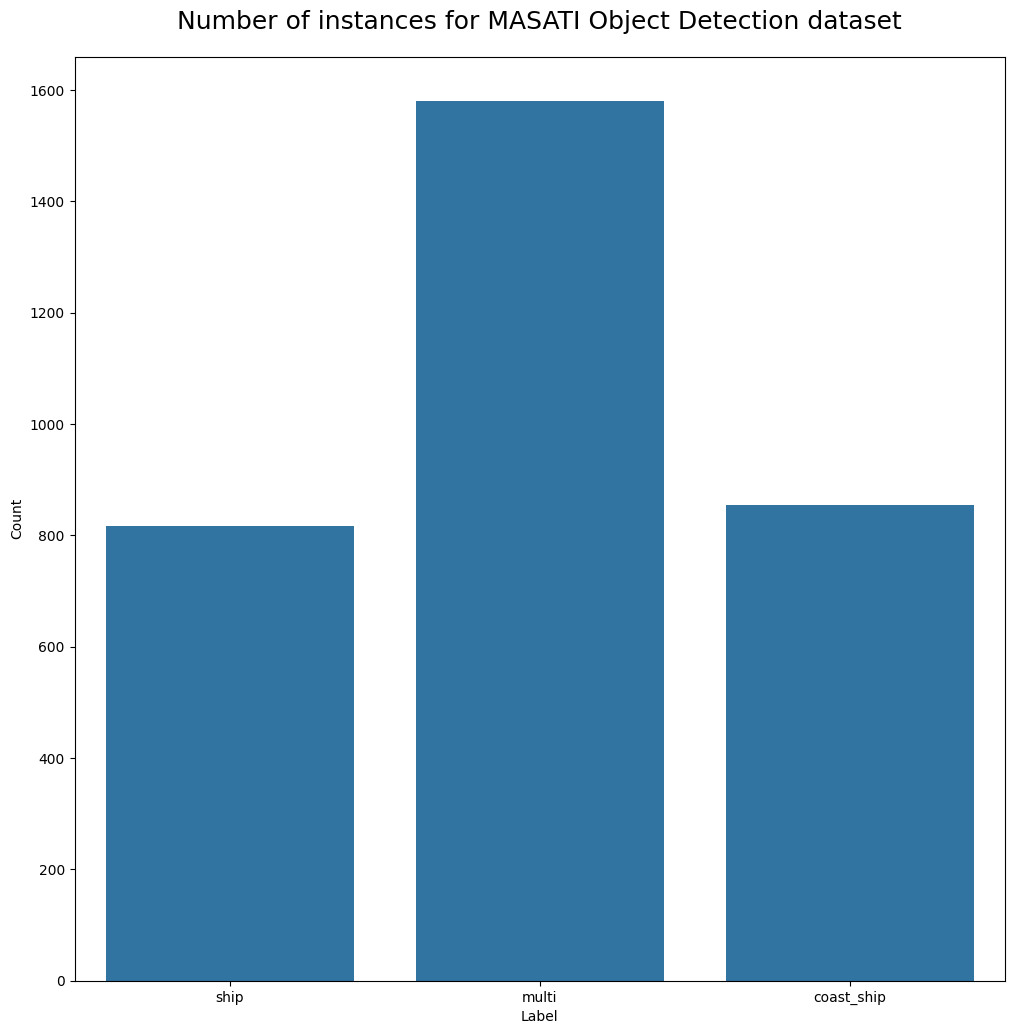

In [54]:
dataset.data_distribution_barchart();

## Load train data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "image_dir": "./data/MASATI/object_detection/images/",
    "annotations_dir": "./data/MASATI/object_detection/labels/",
    "csv_file": "./data/MASATI/object_detection/train.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = MASATIObjectDetectionDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 1896


## Create the model

In [ ]:
epochs = 10
model_directory = "./data/MASATI/object_detection/experiments/"
model_config = {
    "num_classes": 4,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [18]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-05-26 12:04:01,913 INFO Starting training.
training: 100%|██████████| 237/237 [01:19<00:00,  2.98it/s]
2025-05-26 12:05:21,575 INFO epoch: 1, time: 80, loss:  0.20078
testing on train set: 100%|██████████| 237/237 [00:42<00:00,  5.61it/s]
2025-05-26 12:06:07,686 INFO map:0.11788436770439148, map_50:0.2964993715286255, map_75:0.0690191388130188, map_small:0.1061355471611023, map_medium:0.1818915754556656, map_large:0.0, mar_1:0.15676163136959076, mar_10:0.22285838425159454, mar_100:0.24729439616203308, mar_small:0.23672503232955933, mar_medium:0.2772812843322754, mar_large:0.0, map_per_class:tensor(0.1008), tensor(0.0928), tensor(0.1601), mar_100_per_class:tensor(0.1575), tensor(0.2760), tensor(0.3084), classes:tensor(1, dtype=torch.int32), tensor(2, dtype=torch.int32), tensor(3, dtype=torch.int32)
training: 100%|██████████| 237/237 [01:20<00:00,  2.96it/s]
2025-05-26 12:07:27,782 INFO epoch: 2, time: 80, loss:  0.15146
testing on train set: 100%|██████████| 237/237 [00:42<00:00,  

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "image_dir": "./data/MASATI/object_detection/images/",
    "annotations_dir": "./data/MASATI/object_detection/labels/",
    "csv_file":"./data/MASATI/object_detection/val.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = MASATIObjectDetectionDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/MASATI/object_detection/experiments/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 236


2025-05-26 12:25:01,969 INFO Loading checkpoint /home/dragik/data/FAIR_EO/MASATI/object_detection/experiments/checkpoint.pth.tar
2025-05-26 12:25:02,375 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/MASATI/object_detection/experiments/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 30/30 [00:06<00:00,  4.84it/s]


[{'map': 0.23443877696990967,
  'map_50': 0.5595548748970032,
  'map_75': 0.14887714385986328,
  'map_small': 0.2275470495223999,
  'map_medium': 0.2650066912174225,
  'map_large': -1.0,
  'mar_1': 0.25920766592025757,
  'mar_10': 0.33386653661727905,
  'mar_100': 0.3527749180793762,
  'mar_small': 0.33979475498199463,
  'mar_medium': 0.4809523820877075,
  'mar_large': -1.0,
  'map_per_class': [tensor(0.3015), tensor(0.1610), tensor(0.2408)],
  'mar_100_per_class': [tensor(0.4611), tensor(0.2569), tensor(0.3404)],
  'classes': [tensor(1, dtype=torch.int32),
   tensor(2, dtype=torch.int32),
   tensor(3, dtype=torch.int32)]}]

## Predictions

2025-05-26 12:26:56,558 INFO Loading checkpoint /home/dragik/data/FAIR_EO/MASATI/object_detection/experiments/checkpoint.pth.tar
2025-05-26 12:26:56,940 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/MASATI/object_detection/experiments/checkpoint.pth.tar at epoch 11


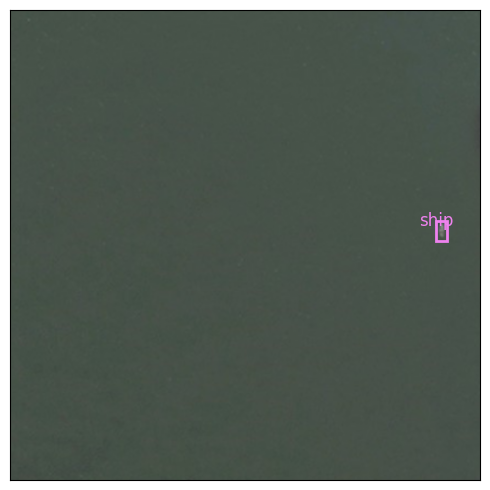

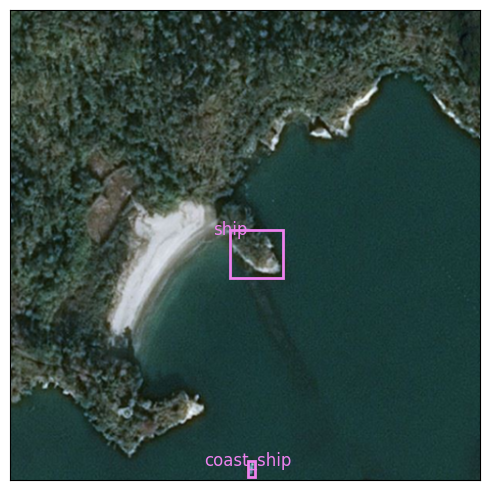

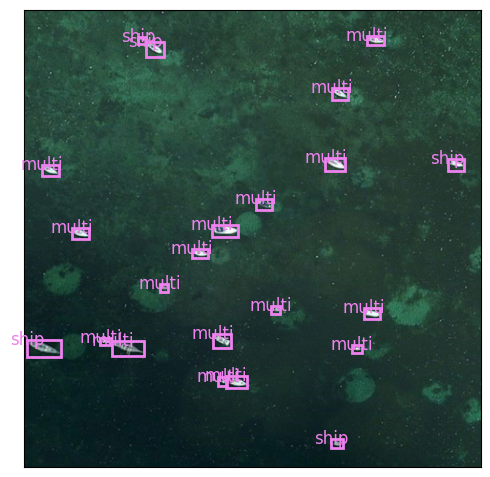

In [ ]:
model_config = {
    "num_classes": 4, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "./data/MASATI/object_detection/experiments/checkpoint.pth.tar"
labels = ["no-data","ship","coast_ship","multi"]
transform = Resize()
model.load_model(model_path)

image = image_loader('./data/MASATI/object_detection/images/ship/s0666.png')
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/MASATI/object_detection/images/coast_ship/x0772.png')
if np.shape(image)[2] == 4:
    image = image[:,:,0:3]
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/MASATI/object_detection/images/multi/m0015.png')
fig = model.detect_objects(image, labels, transform)